# AirQualityUCI 데이터 전처리 및 시각화
이 노트북은 Air Quality UCI 데이터셋을 불러오고, 전처리 및 시각화를 수행

In [1]:
# 1. 라이브러리 임포트
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 2. 데이터 불러오기
df = pd.read_csv("AirQualityUCI.csv", sep=';', decimal=',')

In [3]:
# 3. 마지막 빈 열 제거 + 결측 행 제거
df = df.dropna(how='all', axis=1)
df = df.dropna()

In [4]:
# 4. 날짜-시간 합치기
df["Time"] = df["Time"].astype(str).str.replace(".", ":", regex=False)
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True, errors='coerce')
df = df.dropna(subset=["Datetime"])  # 날짜 파싱 실패한 행 제거
df = df.set_index("Datetime")
df = df.drop(columns=["Date", "Time"])

In [5]:
# 5. 정수 변환 및 결측치(-200) 제거
df = df.apply(pd.to_numeric, errors='coerce')
df[df == -200] = pd.NA
df = df.dropna()

In [6]:
# 6. 데이터 미리보기
df.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
Datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


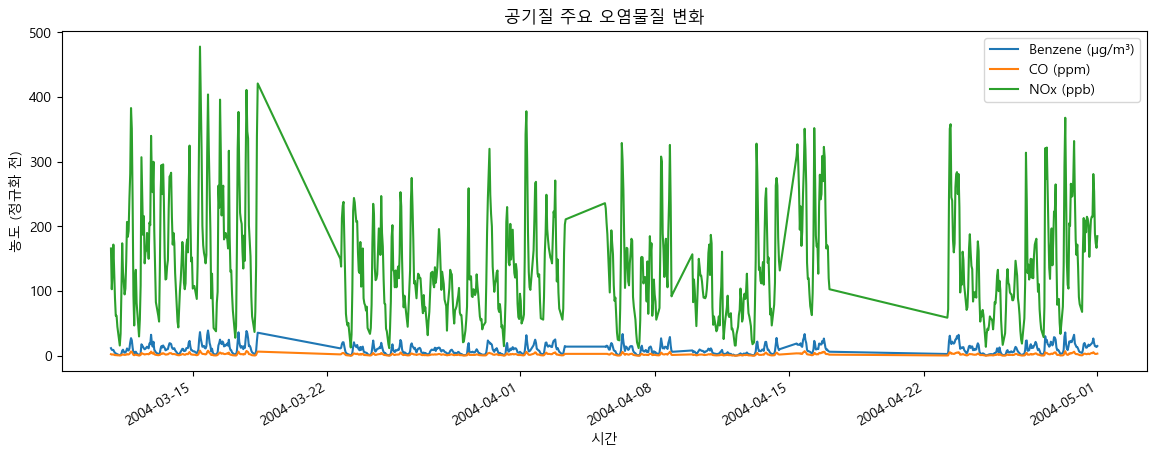

In [7]:
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 기본 한글 폰트
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 부호 깨짐 방지

# 7. 시간 흐름에 따른 주요 센서 및 실제 값 시각화
plt.figure(figsize=(14, 5))
df["C6H6(GT)"].plot(label="Benzene (µg/m³)")
df["CO(GT)"].plot(label="CO (ppm)")
df["NOx(GT)"].plot(label="NOx (ppb)")
plt.legend()
plt.title("공기질 주요 오염물질 변화")
plt.xlabel("시간")
plt.ylabel("농도 (정규화 전)")
plt.show()

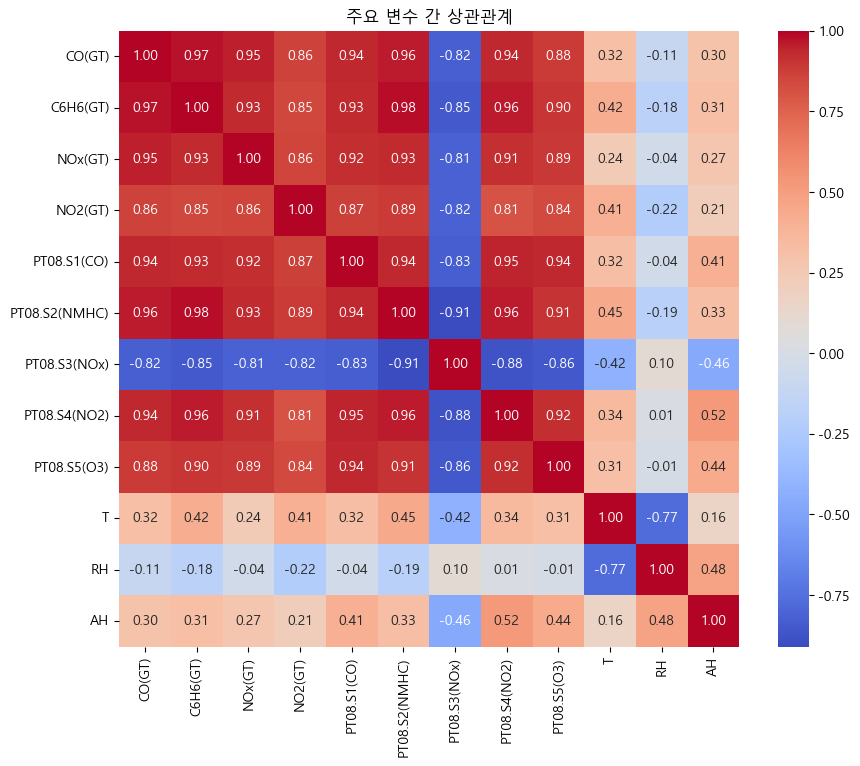

In [8]:
# 8. 주요 변수들 간의 상관관계 행렬
features_of_interest = [
    "CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)",
    "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)",
    "T", "RH", "AH"
]

corr = df[features_of_interest].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("주요 변수 간 상관관계")
plt.show()

In [9]:
#9 상관관계에 따른 변수 그룹 분리
# PPT 기준 변수 그룹 분리
high_corr_features = ["C6H6(GT)", "PT08.S2(NMHC)", "PT08.S5(O3)"]
low_corr_features = ["T", "RH", "AH"]
target = "C6H6(GT)"

# 그룹 구성
high_corr_data = df[high_corr_features]
low_corr_data = df[low_corr_features + [target]]
        

In [11]:
#10 시계열 시퀀스 데이터 생성 및 정규화
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np

def create_sequences(data, seq_length=24):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

scaler_high = MinMaxScaler()
scaler_low = MinMaxScaler()
high_scaled = scaler_high.fit_transform(high_corr_data)
low_scaled = scaler_low.fit_transform(low_corr_data)

X_high, y_high = create_sequences(high_scaled[:, :-1], 24)
X_low, y_low = create_sequences(low_scaled[:, :-1], 24)
y_high = high_scaled[24:, -1]
y_low = low_scaled[24:, -1]

Xh_train, Xh_test, yh_train, yh_test = train_test_split(X_high, y_high, test_size=0.2, shuffle=False)
Xl_train, Xl_test, yl_train, yl_test = train_test_split(X_low, y_low, test_size=0.2, shuffle=False)
        

In [12]:
#11 1D-CNN / LSTM / GRU 모델 구성 및 학습
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, LSTM, GRU

def build_model(model_type='cnn', input_shape=(24, 3)):
    model = Sequential()
    if model_type == 'cnn':
        model.add(Conv1D(64, kernel_size=3, activation='relu', input_shape=input_shape))
        model.add(Conv1D(32, kernel_size=3, activation='relu'))
        model.add(Flatten())
    elif model_type == 'lstm':
        model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
        model.add(LSTM(32))
    elif model_type == 'gru':
        model.add(GRU(64, return_sequences=True, input_shape=input_shape))
        model.add(GRU(32))
    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse')
    return model

def train_and_evaluate(model_type, X_train, y_train, X_test, y_test):
    model = build_model(model_type, X_train.shape[1:])
    history = model.fit(X_train, y_train, epochs=30, batch_size=64,
                        validation_split=0.2, verbose=0)
    preds = model.predict(X_test)
    return history, preds, y_test
        

In [13]:

results = {}
for group, (X_train, y_train, X_test, y_test) in {
    "high": (Xh_train, yh_train, Xh_test, yh_test),
    "low": (Xl_train, yl_train, Xl_test, yl_test)
}.items():
    results[group] = {}
    for model_type in ['cnn', 'lstm', 'gru']:
        hist, preds, y_true = train_and_evaluate(model_type, X_train, y_train, X_test, y_test)
        results[group][model_type] = {'history': hist, 'preds': preds, 'y_test': y_true}
        

C:\Users\jhs40\anaconda3\envs\ai\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


C:\Users\jhs40\anaconda3\envs\ai\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step 


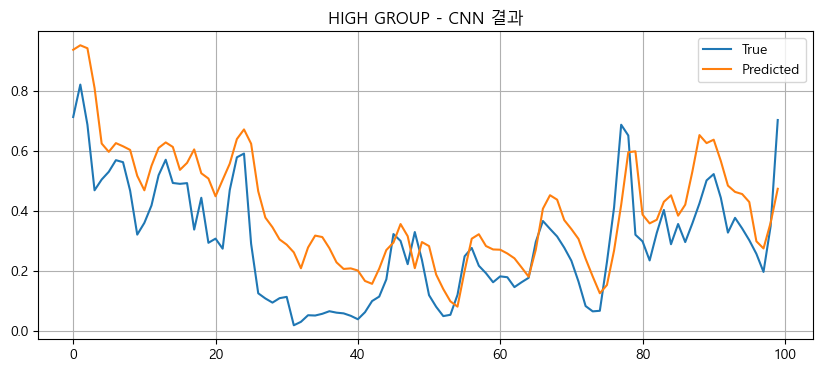

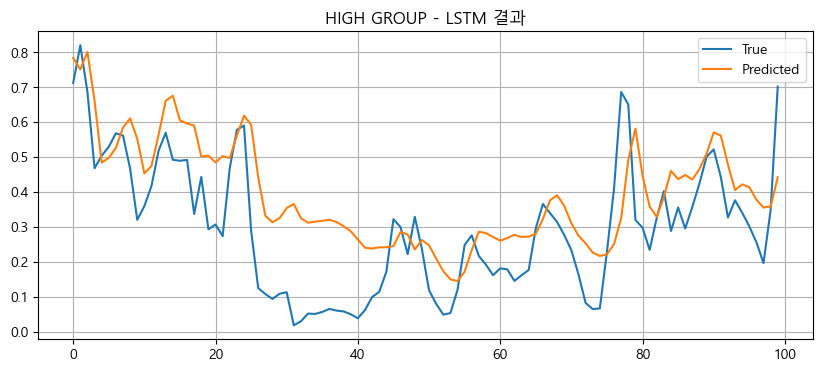

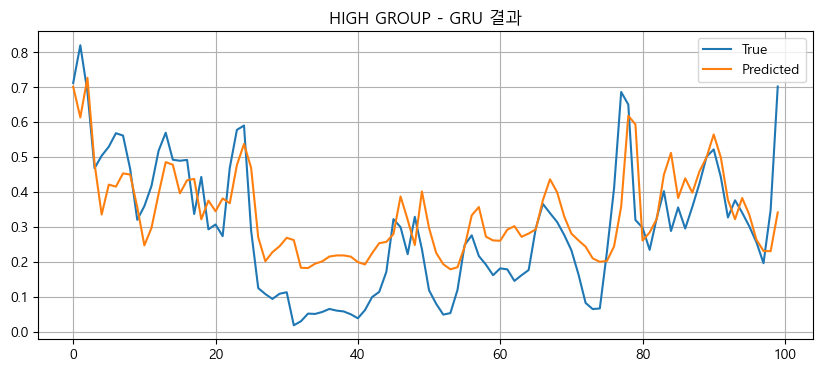

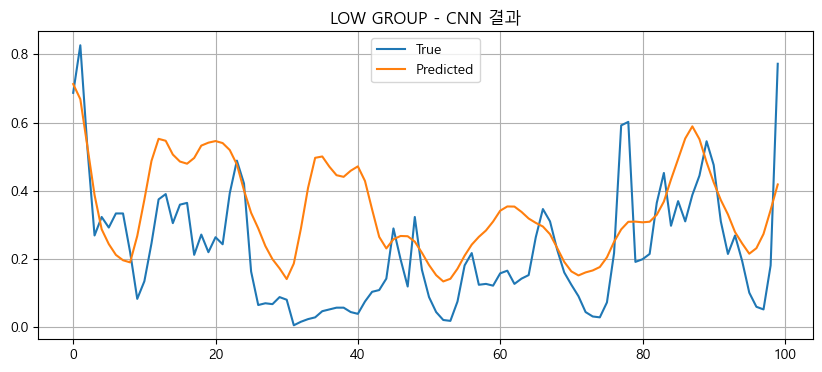

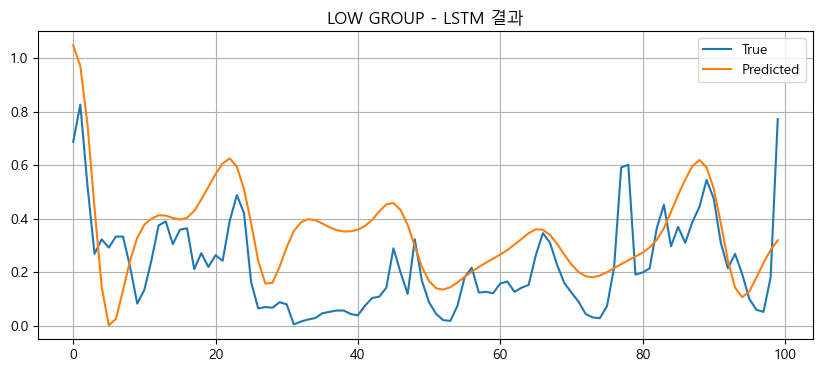

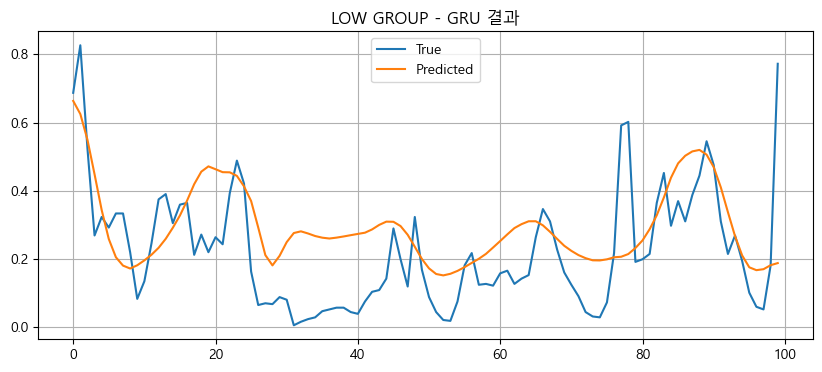

In [14]:
#12 결과 시각화 및 성능 비교
import matplotlib.pyplot as plt

def plot_predictions(group, model_name):
    result = results[group][model_name]
    y_test = result['y_test']
    preds = result['preds']
    plt.figure(figsize=(10, 4))
    plt.plot(y_test[:100], label='True')
    plt.plot(preds[:100], label='Predicted')
    plt.title(f"{group.upper()} GROUP - {model_name.upper()} 결과")
    plt.legend()
    plt.grid(True)
    plt.show()

for group in ['high', 'low']:
    for model in ['cnn', 'lstm', 'gru']:
        plot_predictions(group, model)
        

C:\Users\jhs40\anaconda3\envs\ai\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


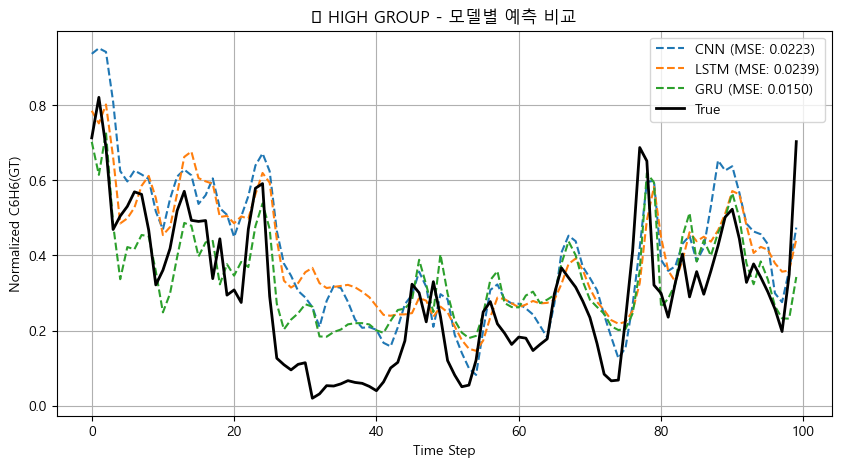

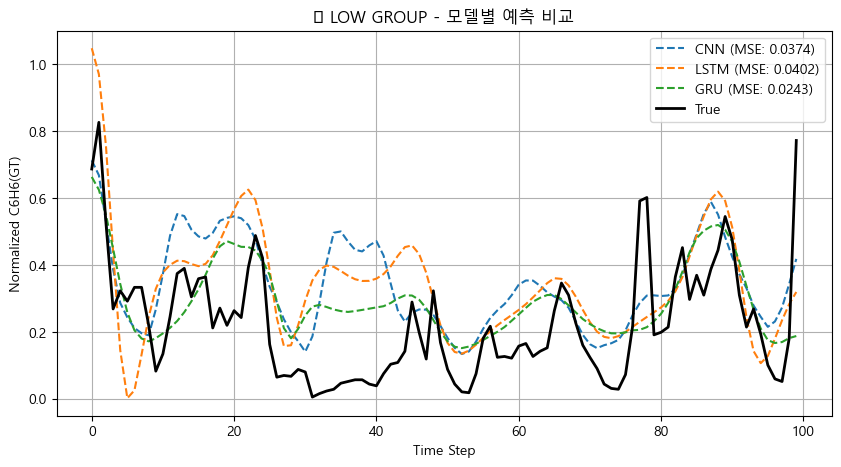

In [15]:
#13 각 모델의 예측 성능 비교 시각화
import matplotlib.pyplot as plt
import numpy as np

def plot_model_comparison(group):
    plt.figure(figsize=(10, 5))
    for model in ['cnn', 'lstm', 'gru']:
        y_true = results[group][model]['y_test'][:100]
        y_pred = results[group][model]['preds'][:100].flatten()
        mse = np.mean((y_true - y_pred) ** 2)
        plt.plot(y_pred, label=f"{model.upper()} (MSE: {mse:.4f})", linestyle='--')
    plt.plot(y_true, label="True", color='black', linewidth=2)
    plt.title(f"📊 {group.upper()} GROUP - 모델별 예측 비교")
    plt.xlabel("Time Step")
    plt.ylabel("Normalized C6H6(GT)")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_model_comparison("high")
plot_model_comparison("low")
        